<a href="https://colab.research.google.com/github/tn652006-droid/MachineLearning/blob/main/Tuan1/BTVN/MachineLearningT1_BTVN_B2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


NGUONG: 0.5
Accuracy: 0.825
Ma tran nham lan:
[[16  3]
 [ 4 17]]

NGUONG: 0.6
Accuracy: 0.825
Ma tran nham lan:
[[16  3]
 [ 4 17]]

NGUONG: 0.7
Accuracy: 0.85
Ma tran nham lan:
[[17  2]
 [ 4 17]]

BANG SO SANH:
 Nguong  Accuracy  Du doan mac benh
    0.5     0.825                20
    0.6     0.825                20
    0.7     0.850                19


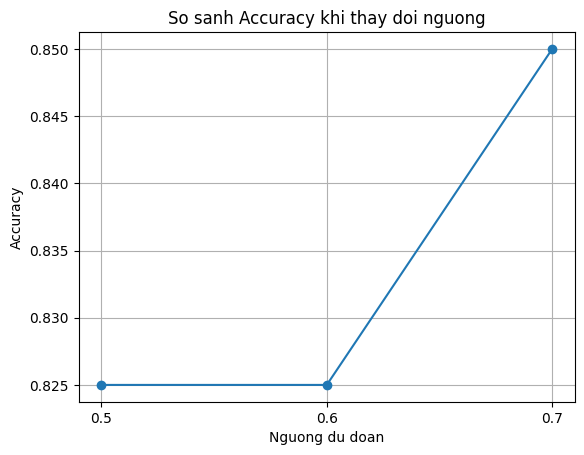

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

# 1. Tao du lieu BMI gia lap
rng = np.random.default_rng(42)
BMI = rng.uniform(16, 40, 200)
p = 1 / (1 + np.exp(-(BMI - 28) / 3))
y = rng.binomial(1, p)
X = BMI.reshape(-1, 1)

# 2. Chia du lieu
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Huan luyen
model = LogisticRegression()
model.fit(X_train, y_train)

# 4. Du doan xac suat
y_prob = model.predict_proba(X_test)[:, 1]

# 5. Thu cac nguong
ket_qua = []

for nguong in [0.5, 0.6, 0.7]:
    y_pred = (y_prob >= nguong).astype(int)
    accuracy = accuracy_score(y_test, y_pred)

    print("\nNGUONG:", nguong)
    print("Accuracy:", round(accuracy, 4))
    print("Ma tran nham lan:")
    print(confusion_matrix(y_test, y_pred))

    ket_qua.append({
        "Nguong": nguong,
        "Accuracy": round(accuracy, 4),
        "Du doan mac benh": int(sum(y_pred == 1))
    })

df = pd.DataFrame(ket_qua)
print("\nBANG SO SANH:")
print(df.to_string(index=False))

# 6. Ve bieu do
plt.plot(df["Nguong"], df["Accuracy"], marker="o")
plt.xlabel("Nguong du doan")
plt.ylabel("Accuracy")
plt.title("So sanh Accuracy khi thay doi nguong")
plt.xticks([0.5, 0.6, 0.7])
plt.grid(True)
plt.show()
